# Modulo 1

## 1-explicar
## 2-descargar


In [1]:
from fredapi import Fred #descarga los datos
import os #crea carpetas 
from datetime import date #para manipular fechas de calendario
import pandas as pd #para crear y manipular dataframe
from dotenv import load_dotenv
import numpy as np #para convertir vectores
import statsmodels.api as sm #regresiones lineales
#recordar usar pip install fredapi - pip install dotenv - pip install ~, en el terminal/consola 

In [2]:
#autentificacion
load_dotenv("FRED_API_KEY.env")
fred = Fred(api_key=os.getenv("FRED_API_KEY"))

#diccionario con las series y su plazo en años
series_cmt = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 3 / 12,
    "DGS6MO": 6 / 12,
    "DGS1": 1.0,
    "DGS2": 2.0,
    "DGS3": 3.0,
    "DGS5": 5.0,
    "DGS7": 7.0,
    "DGS10": 10.0,
    "DGS20": 20.0,
    "DGS30": 30.0,
}
#descargamos y creamos el dataframe dentro del rango 
raw_df = pd.DataFrame(
    {
        codigo: fred.get_series(
            codigo,
            observation_start="2016-10-01",
            observation_end="2026-09-30",
        )
        for codigo in series_cmt
    }
)
raw_df.index = pd.to_datetime(raw_df.index)
raw_df = raw_df.sort_index()

#limpieza de datos
os.makedirs("data/raw", exist_ok=True) #crea la carpeta data y raw dentro
raw_path = f"data/raw/fred_cmt_diario_{date.today().isoformat()}.csv" # nombre el archivo + ultima fecha de descarga
raw_df.to_csv(raw_path)#guarda la tabla tal como se recibe 

mensual_df = raw_df.dropna(how="all").resample("ME").last() #elimina NA y agrupa por mes y ademas toma ultimo dia
mensual_df.index.name = "fecha_cierre_mes" #nombramos la columna de fecha de cierre IMPORTANTE ACA LO AGREGO COMO INDICE, relevante para graficar


os.makedirs("data/processed", exist_ok=True) #creamos la carpeta
# guarda los datos procesados del apartado anterior en la nueva carpeta
mensual_df.to_csv("data/processed/cmt_mensual_cierre.csv") 

mensual_df.head()

,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30
fecha_cierre_mes,,,,,,,,,,,
2016-10-31,0.20,0.34,0.51,0.66,0.86,1.00,1.31,1.62,1.84,2.25,2.58
2016-11-30,0.38,0.48,0.62,0.80,1.11,1.40,1.83,2.18,2.37,2.73,3.02
2016-12-31,0.44,0.51,0.62,0.85,1.20,1.47,1.93,2.25,2.45,2.79,3.06
2017-01-31,0.50,0.52,0.64,0.84,1.19,1.46,1.90,2.24,2.45,2.78,3.05
2017-02-28,0.40,0.53,0.69,0.88,1.22,1.49,1.89,2.19,2.36,2.70,2.97


# Elegir plazos
#### Lo típico es elegir:
#### corto 1mes a 1 año
#### mediano 2 años a 7 años
#### largo 10 años a 30 años
#### eligiendo un punto medio, se va a graficar 6 meses, 5 años y 20 años como corto, mediano y largo plazo respectivamente

In [175]:
# Como yo ya tengo el dataframe, usted puede usar el que vendrá adjunto
import matplotlib.pyplot as plt
columna=np.array(list(series_cmt.keys()))
cp=columna[2]
mp=columna[6]
lp=columna[9]


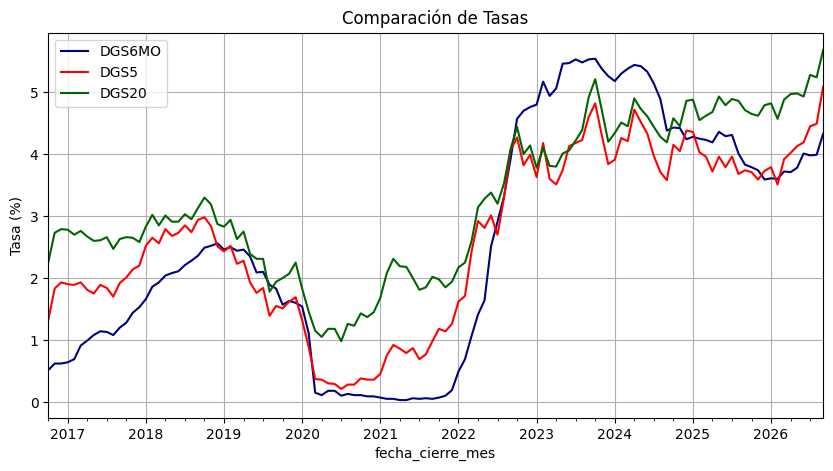

In [176]:
colores=["navy", "red", "darkgreen"]
mensual_df[[cp,mp,lp]].plot(
    figsize=(10, 5),
    title="Comparación de Tasas",
    color=colores)
plt.ylabel("Tasa (%)")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()

# Regresión

#### 4. verficar para tau=1 

In [114]:
m=np.array(list(series_cmt.values()))
tau=1
X_1=(1-np.exp(-m/tau))/(m/tau)
X_2=X_1-np.exp(-m/tau)

In [116]:
scr=0
nobs=0
for i in range(len(mensual_df)):
    y=mensual_df.iloc[i].values
    X=np.column_stack((X_1,X_2))
    X=sm.add_constant(X)
    modelo=sm.OLS(y,X).fit()
    scr+=modelo.ssr
    nobs+=modelo.nobs
scr,nobs    



(23.057530642751978, 1320.0)

In [124]:
def X1(tau):
    return (1-np.exp(-m/tau))/(m/tau)
def X2(tau):
    return X1(tau)-np.exp(-m/tau)

Tau=np.arange(0.1,10,0.01)

In [127]:
scr_total=[]
nobs_tau=[]
for j in Tau:
    nobs=0
    scr=0
    for i in range(len(mensual_df)):
        y=mensual_df.iloc[i].values
        X=np.column_stack((X1(j),X2(j)))
        X=sm.add_constant(X)
        modelo=sm.OLS(y,X).fit()
        scr+=modelo.ssr
        nobs+=modelo.nobs
    scr_total.append(scr)
    nobs_tau.append(nobs)

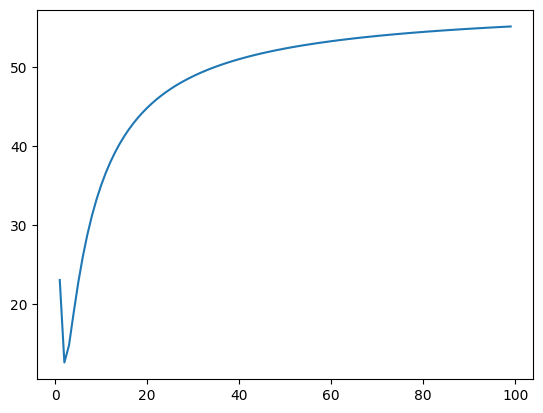

In [123]:
plt.plot(Tau,scr_total)

In [128]:
indice=np.argmin(scr_total)
tau_optimo=Tau[indice]
scr_min=scr_total[indice]
tau_optimo,scr_min, nobs_tau[indice]

(2.089999999999999, 12.580904471699776, 1320.0)

In [134]:
beta_0=[]
beta_1=[]
beta_2=[]
for i in range(len(mensual_df)):
        y=mensual_df.iloc[i].values
        X=np.column_stack((X1(tau_optimo),X2(tau_optimo)))
        X=sm.add_constant(X)
        modelo=sm.OLS(y,X).fit()
        beta_0.append(modelo.params[0])
        beta_1.append(modelo.params[1])
        beta_2.append(modelo.params[2])

In [ ]:
mensual_df_regresores=mensual_df
mensual_df_regresores["beta_0"]=beta_0
mensual_df_regresores["beta_1"]=beta_1
mensual_df_regresores["beta_2"]=beta_2

,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30,beta_0,beta_1,beta_2
fecha_cierre_mes,,,,,,,,,,,,,,
2016-10-31,0.20,0.34,0.51,0.66,0.86,1.00,1.31,1.62,1.84,2.25,2.58,2.708754,-2.397148,-1.456680
2016-11-30,0.38,0.48,0.62,0.80,1.11,1.40,1.83,2.18,2.37,2.73,3.02,3.207540,-2.830170,-1.023272
2016-12-31,0.44,0.51,0.62,0.85,1.20,1.47,1.93,2.25,2.45,2.79,3.06,3.246782,-2.848134,-0.845612
2017-01-31,0.50,0.52,0.64,0.84,1.19,1.46,1.90,2.24,2.45,2.78,3.05,3.251978,-2.816430,-0.978688
2017-02-28,0.40,0.53,0.69,0.88,1.22,1.49,1.89,2.19,2.36,2.70,2.97,3.110852,-2.697446,-0.644024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-31,3.72,3.69,3.78,3.79,3.98,4.06,4.13,4.27,4.45,4.98,4.99,5.166549,-1.414953,-1.507648
2026-06-30,3.70,3.87,4.01,3.98,4.14,4.15,4.19,4.30,4.44,4.93,4.91,5.024973,-1.151845,-1.065975
2026-07-31,3.78,3.83,3.98,4.08,4.28,4.34,4.45,4.59,4.75,5.28,5.27,5.413700,-1.554358,-1.021461


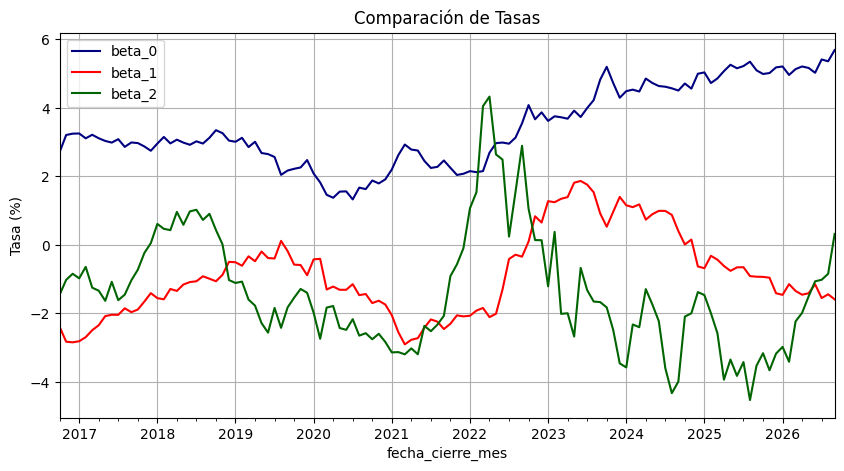

In [145]:
colores=["navy", "red", "darkgreen"]
mensual_df_regresores[["beta_0","beta_1","beta_2"]].plot(
    figsize=(10, 5),
    title="Comparación de Tasas",
    color=colores)
plt.ylabel("Tasa (%)")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()


In [169]:
feds = pd.read_csv("feds200628.csv", skiprows=9)

feds["Date"] = pd.to_datetime(feds["Date"])

feds = feds[
    (feds["Date"] >= "2016-10-01") &
    (feds["Date"] <= "2026-09-30")
]

feds = feds.set_index("Date")

feds_mensual = feds.resample("ME").last()


In [163]:
feds.head()

,BETA0,BETA1,BETA2,BETA3,SVEN1F01,SVEN1F04,SVEN1F09,SVENF01,SVENF02,SVENF03,...,SVENY23,SVENY24,SVENY25,SVENY26,SVENY27,SVENY28,SVENY29,SVENY30,TAU1,TAU2
Date,,,,,,,,,,,,,,,,,,,,,
2016-10-03,4.060191,-3.441743,-2.355574,-4.417859,0.9445,1.7515,2.3100,0.7943,1.0971,1.3949,...,2.2950,2.3340,2.3722,2.4094,2.4459,2.4814,2.5161,2.5499,2.058397,8.880804
2016-10-04,4.272225,-3.690955,-2.213812,-4.566190,0.9935,1.8099,2.4006,0.8336,1.1503,1.4484,...,2.3641,2.4029,2.4410,2.4784,2.5150,2.5508,2.5858,2.6201,2.298547,9.656414
2016-10-05,4.357664,-3.807501,-2.033362,-4.629088,1.0310,1.8477,2.4375,0.8612,1.1932,1.4910,...,2.3979,2.4367,2.4747,2.5120,2.5486,2.5844,2.6196,2.6540,2.421928,9.934867
2016-10-06,4.253072,-3.666345,-2.165721,-4.444276,1.0493,1.8941,2.4622,0.8752,1.2177,1.5290,...,2.4265,2.4651,2.5030,2.5400,2.5762,2.6117,2.6463,2.6801,2.190994,9.309171
2016-10-07,4.068417,-3.528982,-1.745509,-3.859760,1.0447,1.8511,2.4659,0.8731,1.2067,1.4998,...,2.4283,2.4663,2.5034,2.5394,2.5744,2.6085,2.6415,2.6737,2.404160,8.882798


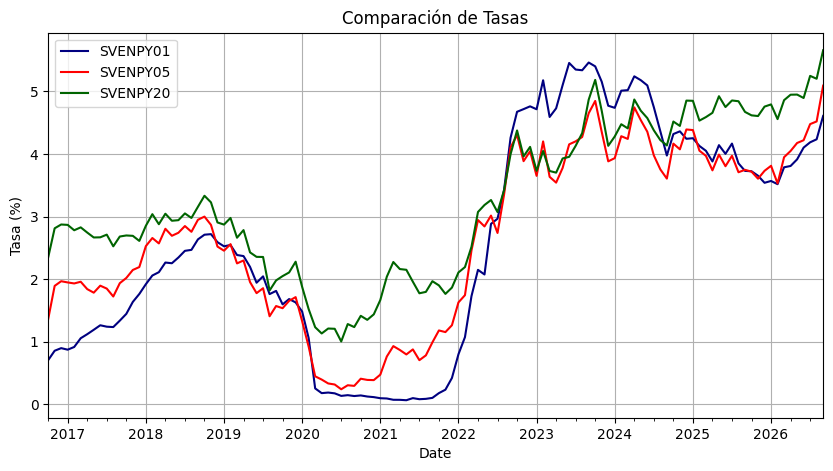

In [170]:
colores=["navy", "red", "darkgreen"]
feds_mensual[["SVENPY01","SVENPY05","SVENPY20"]].plot(
    figsize=(10, 5),
    title="Comparación de Tasas",
    color=colores)
plt.ylabel("Tasa (%)")
plt.legend(loc="upper left")
plt.grid(True)
plt.show()

In [154]:
feds.head()


,Date,BETA0,BETA1,BETA2,BETA3,SVEN1F01,SVEN1F04,SVEN1F09,SVENF01,SVENF02,...,SVENY23,SVENY24,SVENY25,SVENY26,SVENY27,SVENY28,SVENY29,SVENY30,TAU1,TAU2
0,1961-06-14,3.917606,-1.277955,-1.949397,0.0,3.8067,3.9562,NaN,3.5492,3.8825,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.339218,-999.99
1,1961-06-15,3.978498,-1.257404,-2.247617,0.0,3.8694,4.0183,NaN,3.5997,3.9460,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.325775,-999.99
2,1961-06-16,3.984350,-1.429538,-1.885024,0.0,3.8634,4.0242,NaN,3.5957,3.9448,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.348817,-999.99
3,1961-06-19,4.004379,-0.723311,-3.310743,0.0,3.9196,4.0447,NaN,3.6447,3.9842,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.282087,-999.99
4,1961-06-20,3.985789,-0.900432,-2.844809,0.0,3.8732,4.0257,NaN,3.5845,3.9552,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.310316,-999.99


In [167]:
mp

'DGS5'